In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    TargetEncoder
)
from sklearn.feature_extraction import FeatureHasher

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.compose import make_column_transformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score


In [3]:
# Revisit the OKCupid data
df = pd.read_csv("../04_categorical/profiles_revised.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59946 entries, 0 to 59945
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          59946 non-null  int64  
 1   body_type    54650 non-null  str    
 2   diet         35551 non-null  str    
 3   drinks       56961 non-null  str    
 4   drugs        45866 non-null  str    
 5   education    53318 non-null  str    
 6   ethnicity    54266 non-null  str    
 7   height       59943 non-null  float64
 8   income       59946 non-null  int64  
 9   job          51748 non-null  str    
 10  offspring    24385 non-null  str    
 11  orientation  59946 non-null  str    
 12  pets         40025 non-null  str    
 13  religion     39720 non-null  str    
 14  sex          59946 non-null  str    
 15  sign         48890 non-null  str    
 16  smokes       54434 non-null  str    
 17  speaks       59896 non-null  str    
 18  status       59946 non-null  str    
dtypes: float64(1), 

In [4]:
# Stratify on the drinks category because that's what we did in lecture 4
df["drinks"] = df["drinks"].replace(np.nan, "Unknown")
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["drinks"])

In [5]:
# revisit cardinality
print("Feature     Count")
# Assuming that str is categorical, could be bad assumption
for feat in train.select_dtypes(include="str").columns:
    print(f"{feat:12}{train[feat].nunique()}")

Feature     Count
body_type   12
diet        18
drinks      7
drugs       3
education   32
ethnicity   208
job         21
offspring   15
orientation 3
pets        15
religion    45
sex         2
sign        48
smokes      5
speaks      6440
status      5


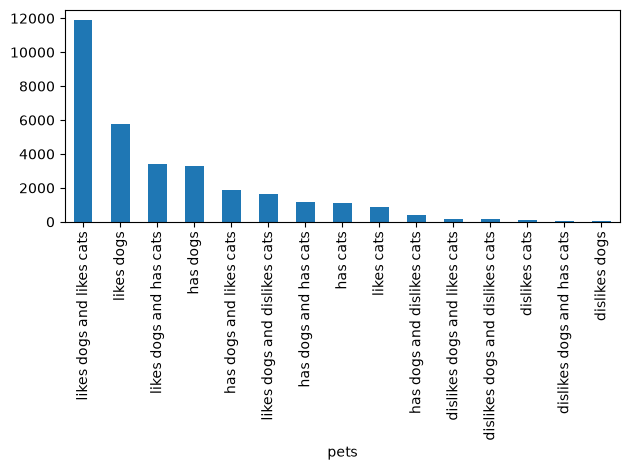

In [6]:
# let's check the "pets" category
ax = train["pets"].value_counts().plot.bar()
plt.tight_layout()
plt.savefig("../../img/08-pets-dist.png")

## Combining infrequent categories

In [7]:
# TODO: see how it changes with max_categories
pet_enc = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_pets = pet_enc.fit_transform(train[["pets"]])
one_hot_pets

,pets_dislikes cats,pets_dislikes dogs,pets_dislikes dogs and dislikes cats,pets_dislikes dogs and has cats,pets_dislikes dogs and likes cats,pets_has cats,pets_has dogs,pets_has dogs and dislikes cats,pets_has dogs and has cats,pets_has dogs and likes cats,pets_likes cats,pets_likes dogs,pets_likes dogs and dislikes cats,pets_likes dogs and has cats,pets_likes dogs and likes cats,pets_nan
16487,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
23577,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19304,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
20471,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
22160,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2623,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
24788,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
25336,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
32834,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [8]:
one_hot_pets.sum(axis=0)

pets_dislikes cats                         96.0
pets_dislikes dogs                         33.0
pets_dislikes dogs and dislikes cats      160.0
pets_dislikes dogs and has cats            60.0
pets_dislikes dogs and likes cats         190.0
pets_has cats                            1118.0
pets_has dogs                            3311.0
pets_has dogs and dislikes cats           424.0
pets_has dogs and has cats               1192.0
pets_has dogs and likes cats             1899.0
pets_likes cats                           850.0
pets_likes dogs                          5780.0
pets_likes dogs and dislikes cats        1637.0
pets_likes dogs and has cats             3439.0
pets_likes dogs and likes cats          11894.0
pets_nan                                15873.0
dtype: float64

## Feature Hashing
For very high cardinality strings (or other iterables)

In [9]:
train["speaks"].value_counts()

speaks
english                                                                                  17487
english (fluently)                                                                        5355
english (fluently), spanish (poorly)                                                      1644
english (fluently), spanish (okay)                                                        1532
english (fluently), spanish (fluently)                                                    1031
                                                                                         ...  
english, c++ (okay), french (okay)                                                           1
french (fluently), german (fluently), spanish (fluently), english                            1
english (fluently), french (okay), c++ (okay), esperanto (poorly), chinese (poorly)          1
english, yiddish (fluently), tagalog (fluently), sanskrit (fluently), lisp (fluently)        1
english, polish, german, russian           

In [10]:
# feature hasher needs lists of strings, and can't handle nans
train.fillna({"speaks": ""}, inplace=True)
language_enc = FeatureHasher(n_features=8, input_type="string")
lang_hash = language_enc.fit_transform(train["speaks"].str.split(",")).todense()

In [11]:
test = [["french (okay)"], ["english (fluently), spanish (poorly)"],["english, python (okay)", "c++", "japanese"], ["a", "b", "c", "d", "1234"]]
language_enc.transform(test).todense()

matrix([[ 0.,  0.,  0.,  0.,  0., -1.,  0.,  0.],
        [ 0.,  0., -1.,  0.,  0.,  0.,  0.,  0.],
        [ 0.,  0., -1.,  1.,  0.,  0.,  0., -1.],
        [ 0., -1.,  1.,  2.,  0., -1.,  0.,  0.]])

## Target encoding
For high cardinal features with a relationship to the target

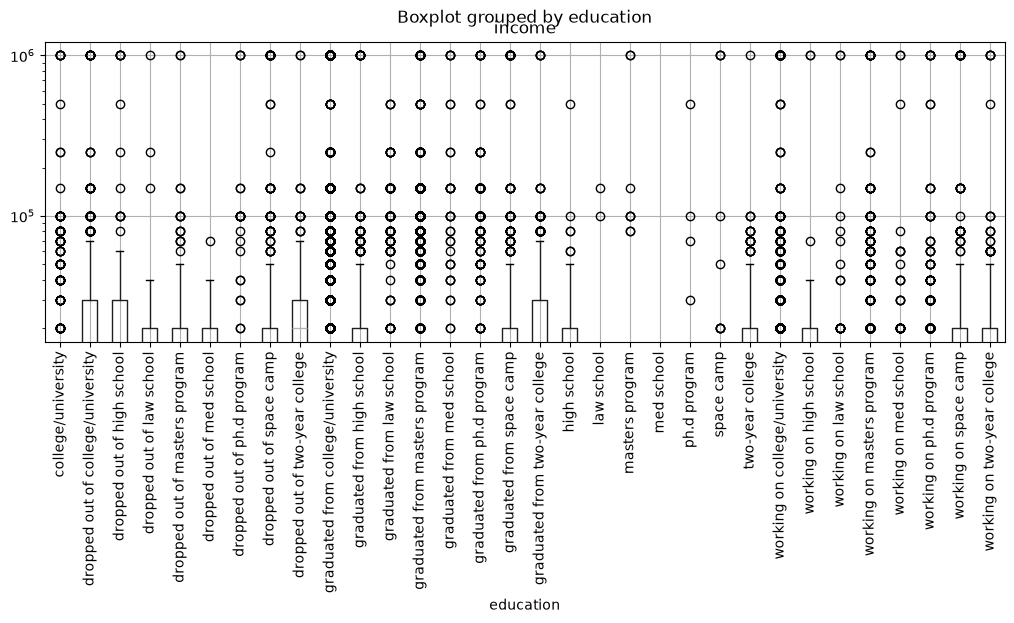

In [18]:
# income vs education
ax = train.boxplot(column="income", by="education", rot=90, figsize=(12, 4))
ax.set_yscale("log")
# hmmm... not sure if this is at all useful

In [46]:
edu_encoder = TargetEncoder(target_type="continuous")

# important! Use fit_transform with this type of encoder
edu_feat = edu_encoder.fit_transform(train[["education"]],train["income"])
order = edu_encoder.encodings_[0].argsort()

for o in order:
    print(f"{edu_encoder.categories_[0][o]:35} ${edu_encoder.encodings_[0][o]:,.2f}")

med school                          $-1.00
                                nan $11,432.16
working on law school               $13,000.29
dropped out of med school           $13,669.76
working on ph.d program             $15,186.34
working on two-year college         $15,198.78
graduated from law school           $15,288.82
working on masters program          $16,068.26
law school                          $16,712.13
high school                         $17,958.64
graduated from masters program      $18,420.80
working on med school               $18,879.45
graduated from college/university   $19,039.02
graduated from two-year college     $19,066.97
two-year college                    $19,109.49
working on college/university       $19,977.21
college/university                  $20,295.56
graduated from med school           $21,693.70
graduated from high school          $22,640.39
masters program                     $24,772.04
graduated from ph.d program         $26,225.31
dropped out of ma